In [1]:
import numpy as np
import pandas as pd
import rdata
import os
from itertools import product

In [2]:
# Convert into rda file
simulators = ["cloudsim", "networkcloudsim", "dissectcf", "opendc", "simgrid"]

if not os.path.exists("simulator_energies.rda"):
    sim_dfs = {}
    for simulator in simulators:
        df = pd.read_csv(f"energy/{simulator}.energy")
        df = df[df["time"] <= 300]
        sim_dfs[simulator] = df
        
    # Write data into rda file
    print("Creating rda file with all results")
    rdata.write_rda("simulator_energies.rda", sim_dfs)
else:
    # Read data from the rda file
    print("Reading rda file with all results")
    sim_dfs = rdata.read_rda("simulator_energies.rda")
    print(sim_dfs)

Reading rda file with all results
{'cloudsim':           time  joules_total    joules  time_diff  host_power  joules_correct  \
0          1.0      0.000000       NaN        NaN         NaN             NaN   
1          2.0      5.334625  5.334625        NaN         NaN             NaN   
2          3.0     10.669251  5.334625        NaN         NaN             NaN   
3          4.0     16.003876  5.334625        NaN         NaN             NaN   
4          5.0     21.338502  5.334625        5.0    2.432917       12.107016   
...        ...           ...       ...        ...         ...             ...   
1155834  296.0   2327.415272  7.889543        NaN         NaN             NaN   
1155835  297.0   2335.304815  7.889543        NaN         NaN             NaN   
1155836  298.0   2343.194358  7.889543        NaN         NaN             NaN   
1155837  299.0   2351.083902  7.889543        NaN         NaN             NaN   
1155838  300.0   2358.973445  7.889543        5.0    4.585710 

# Overview

## Mean per powermodel - simulator combination

In [3]:
powermodel_overview = {}

for simulator, sim_df in sim_dfs.items():
    sim_df["rel_error_total_abs"] = sim_df["rel_error_total"].abs()
    df = sim_df.dropna(subset=["powermodel", "workload", "rel_error_total_abs"])
    df = df[df["time"] == df["time"].max()]
    grouped = df.groupby(["powermodel", "workload"])["rel_error_total_abs"].mean().round(2).unstack("workload")
    powermodel_overview[simulator] = grouped

overview_df = pd.concat(powermodel_overview, axis=1)
overview_df[("Mean", "")] = overview_df.mean(axis=1).round(2)
mean_row = overview_df.mean(axis=0).round(2)
mean_row.name = "Mean"
overview_df = pd.concat([overview_df, pd.DataFrame([mean_row])])

overview_df


cloudsim networkcloudsim dissectcf  opendc simgrid                    \
workload    trace   trace-network       swf parquet  simple simple-with-comms   
cubic        0.54            0.54       NaN    0.41     NaN               NaN   
linear       0.74            0.74      0.71    0.41    0.42              0.42   
sqrt         0.80            0.81       NaN    0.37     NaN               NaN   
square       0.63            0.63       NaN    0.41     NaN               NaN   
constant      NaN             NaN      0.44    0.14     NaN               NaN   
Mean         0.68            0.68      0.57    0.35    0.42              0.42   

          Mean  
workload        
cubic     0.50  
linear    0.57  
sqrt      0.66  
square    0.56  
constant  0.29  
Mean      0.52

In [4]:
best_combos = {
    "cloudsim": "cubic",
    "networkcloudsim": "cubic",
    "dissectcf":  "constant",
    "opendc": "constant",
    "simgrid": "linear"
}

# Check significant differences

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import shapiro
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal
from functools import reduce

In [6]:
# This variable will store all p-values computed in the check_if_diff function for later use (e.g., for multiple testing correction)
p_values = [] 

def check_if_diff(df, var_name):
    df = df[["joules_total", var_name]]
    # Check for normality
    if len(df[var_name].unique()) < 2:
        return

    if len(df[var_name].unique()) < 4:
        for var in df[var_name].unique():
            subset = df[df[var_name] == var]["joules_total"].dropna()

            plt.figure(figsize=(2, 2))
            stats.probplot(subset, dist="norm", plot=plt)
            plt.title(f"Q–Q Plot for {var_name}: {var}")
            plt.xlabel("Theoretical Quantiles")
            plt.ylabel("Sample Quantiles")
            plt.grid(True)
            plt.tight_layout()
            plt.show()

    for var in df[var_name].unique():
        subset = df[df[var_name] == var]["joules_total"].dropna()
        stat, p = shapiro(subset)
        print(f"{var}: p = {p} {'(normal)' if p > 0.05 else '(not normal)'}")
        assert p < 0.05
    
    if len(df[var_name].unique()) == 2:
        A = df[df[var_name] == df[var_name].unique()[0]]["joules_total"]
        B = df[df[var_name] == df[var_name].unique()[1]]["joules_total"]

        u_stat, p_val = mannwhitneyu(A, B, alternative='two-sided')
        print(f"p-value Mann-Whitney U test: {p_val}")
    else:
        ABCs = [df[df[var_name] == x]["joules_total"] for x in df[var_name].unique()]

        h_stat, p_val = kruskal(*ABCs)
        print(f"p-value Kruskal–Wallis test = {p_val}")

    # Store the p-value for later use (e.g., for multiple testing correction)
    p_values.append(p_val)
    if p_val > 0.05:
        print("Not significantly different!")
    else:
        print("Significantly Different!")



## Simgrid with or without communication

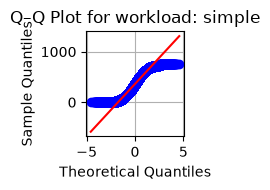

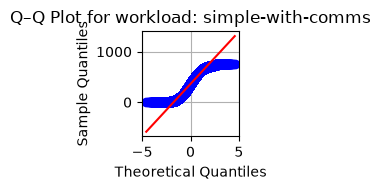

simple: p = 2.807520278649447e-110 (not normal)
simple-with-comms: p = 2.807520278649447e-110 (not normal)
p-value Mann-Whitney U test: 1.0
Not significantly different!


/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 288960.
  res = hypotest_fun_out(*samples, **kwds)
/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 288960.
  res = hypotest_fun_out(*samples, **kwds)


In [7]:
check_if_diff(sim_dfs["simgrid"], "workload")

The p-value is greater than 0.05, which means that we can confidently assume that there is no significant difference between the simulated energy difference with or without communication being simulated.
We therefore get rid of the simple-with-comms measurements.

In [8]:
print(sim_dfs)
simgrid_df = sim_dfs["simgrid"]

sim_dfs["simgrid"] = simgrid_df[simgrid_df["workload"] == "simple"]
#sim_dfs["simgrid-with-comms"] = simgrid_df[simgrid_df["workload"] == "simple-with-comms"].copy()
#sim_dfs["simgrid"] = simgrid_df[simgrid_df["workload"] == "simple"]
#simulators.append("simgrid-with-comms")


{'cloudsim':           time  joules_total    joules  time_diff  host_power  joules_correct  \
0          1.0      0.000000       NaN        NaN         NaN             NaN   
1          2.0      5.334625  5.334625        NaN         NaN             NaN   
2          3.0     10.669251  5.334625        NaN         NaN             NaN   
3          4.0     16.003876  5.334625        NaN         NaN             NaN   
4          5.0     21.338502  5.334625        5.0    2.432917       12.107016   
...        ...           ...       ...        ...         ...             ...   
1155834  296.0   2327.415272  7.889543        NaN         NaN             NaN   
1155835  297.0   2335.304815  7.889543        NaN         NaN             NaN   
1155836  298.0   2343.194358  7.889543        NaN         NaN             NaN   
1155837  299.0   2351.083902  7.889543        NaN         NaN             NaN   
1155838  300.0   2358.973445  7.889543        5.0    4.585710       25.004627   

         joule

## Create Super DF

In [9]:
dfs = []
for simulator, sim_df in sim_dfs.items():
    df = sim_df
    df["simulator"] = simulator
    group_cols = [col for col in df.columns if col != "run" and col != "joules_total"]
    df_avg = df.groupby(group_cols)["joules_total"].mean().reset_index()
    
    dfs.append(df_avg)

super_df = reduce(
    lambda left, right: pd.merge(left, right, on=list(df_avg.columns), how="outer", suffixes=('', '_dup')),
    dfs
)

print(super_df["simulator"].unique())
super_df

<StringArray>
['simgrid', 'opendc', 'cloudsim', 'networkcloudsim', 'dissectcf']
Length: 5, dtype: str


,time,joules,time_diff,host_power,joules_correct,joules_total_correct,error_total,error,rel_error_total,rel_error,...,powermodel,workload,test_system,scenario,users,repetition,rel_error_total_abs,simulator,joules_total,policy_dup
0,5.0,2.378730,5.0,4.857042,24.252698,24.252698,12.323698,12.323698,0.508137,0.508137,...,linear,simple,trainticket,A,100,27,0.508137,simgrid,11.929000,<NA>
1,5.0,2.378730,5.0,4.867932,24.252004,24.252004,12.320804,12.320804,0.508032,0.508032,...,linear,simple,trainticket,B,1000,13,0.508032,simgrid,11.931200,<NA>
2,5.0,2.378740,5.0,5.200397,25.818503,25.818503,13.861003,13.861003,0.536863,0.536863,...,linear,simple,trainticket,A,100,3,0.536863,simgrid,11.957500,<NA>
3,5.0,2.378740,5.0,3.242176,16.237581,16.237581,4.306681,4.306681,0.265229,0.265229,...,linear,simple,trainticket,A,1000,29,0.265229,simgrid,11.930900,<NA>
4,5.0,2.378740,5.0,3.002478,15.002733,15.002733,3.086833,3.086833,0.205751,0.205751,...,linear,simple,sockshop,B,100,17,0.205751,simgrid,11.915900,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30251,300.0,15.779087,5.0,5.070895,23.399288,1362.750871,-964.664401,-23.937972,-0.707880,-1.023021,...,linear,swf,trainticket,B,100,28,0.707880,dissectcf,2327.415272,<NA>
30252,300.0,15.779087,5.0,6.319752,34.057651,1465.367341,-862.047930,-13.279609,-0.588281,-0.389916,...,linear,swf,trainticket,B,1000,8,0.588281,dissectcf,2327.415272,<NA>
30253,300.0,15.779087,5.0,4.585710,25.004627,1462.116231,-865.299041,-22.332633,-0.591813,-0.893140,...,linear,swf,trainticket,B,1000,12,0.591813,dissectcf,2327.415272,<NA>
30254,300.0,15.779087,5.0,5.444233,29.443945,1464.594262,-862.821009,-17.893315,-0.589119,-0.607708,...,linear,swf,trainticket,B,1000,13,0.589119,dissectcf,2327.415272,<NA>


## Between all simulators

In [10]:
check_if_diff(super_df, "simulator")


simgrid: p = 1.1490869999411866e-23 (not normal)
opendc: p = 6.292312543120171e-50 (not normal)
cloudsim: p = 2.6135253470461e-39 (not normal)
networkcloudsim: p = 2.663271699578547e-39 (not normal)
dissectcf: p = 6.0760237423325e-47 (not normal)
p-value Kruskal–Wallis test = 0.0
Significantly Different!


/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9520.
  res = hypotest_fun_out(*samples, **kwds)
/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7552.
  res = hypotest_fun_out(*samples, **kwds)
/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7552.
  res = hypotest_fun_out(*samples, **kwds)


### Between CloudSim and NetworkCloudSim

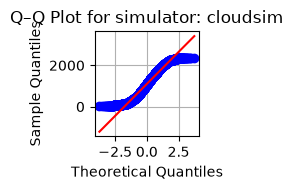

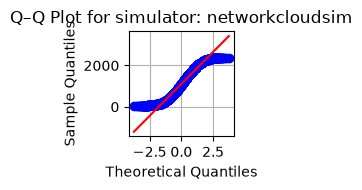

cloudsim: p = 2.6135253470461e-39 (not normal)
networkcloudsim: p = 2.663271699578547e-39 (not normal)
p-value Mann-Whitney U test: 0.31116496485516876
Not significantly different!


/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7552.
  res = hypotest_fun_out(*samples, **kwds)
/Users/ivano/Documents/Development/simpat-2026-cloud-simulators-energy/evaluation/.venv/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7552.
  res = hypotest_fun_out(*samples, **kwds)


In [11]:
check_if_diff(super_df[(super_df["simulator"] == "cloudsim") | (super_df["simulator"] == "networkcloudsim")], "simulator")

## Powermodels

### Between powermodels

LINEAR
simgrid: p = 1.1490869999411866e-23 (not normal)
opendc: p = 4.4791084947849346e-24 (not normal)
networkcloudsim: p = 9.273691405308538e-22 (not normal)
cloudsim: p = 9.05694176833969e-22 (not normal)
dissectcf: p = 1.5102582064747324e-21 (not normal)
p-value Kruskal–Wallis test = 0.0
Significantly Different!
CUBIC


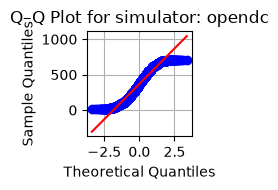

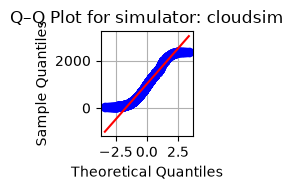

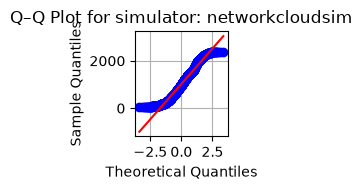

opendc: p = 3.695144361893302e-24 (not normal)
cloudsim: p = 1.05175040299008e-20 (not normal)
networkcloudsim: p = 1.0190624051446849e-20 (not normal)
p-value Kruskal–Wallis test = 0.0
Significantly Different!
SQUARE


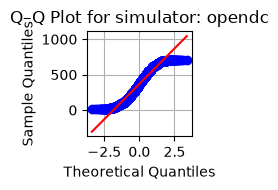

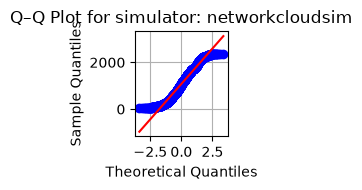

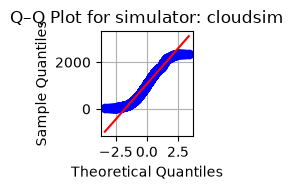

opendc: p = 3.69980688182608e-24 (not normal)
networkcloudsim: p = 4.2664419459798305e-20 (not normal)
cloudsim: p = 4.201483009970521e-20 (not normal)
p-value Kruskal–Wallis test = 0.0
Significantly Different!
SQRT


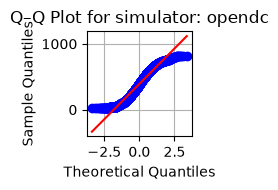

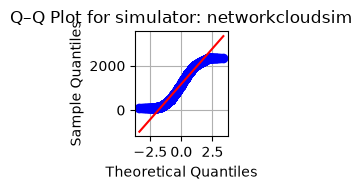

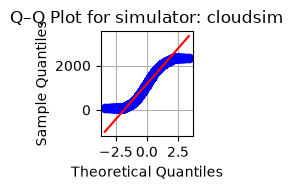

opendc: p = 5.445303265629575e-23 (not normal)
networkcloudsim: p = 4.8900518786328127e-23 (not normal)
cloudsim: p = 4.8328936317369457e-23 (not normal)
p-value Kruskal–Wallis test = 0.0
Significantly Different!
CONSTANT


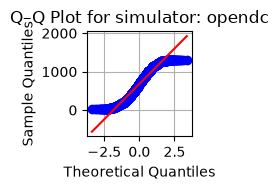

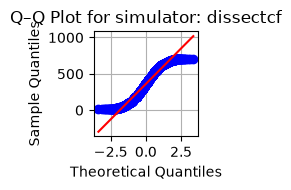

opendc: p = 3.695112487980541e-24 (not normal)
dissectcf: p = 1.2651506724510152e-23 (not normal)
p-value Mann-Whitney U test: 1.0818026028010726e-148
Significantly Different!


In [12]:
for powermodel in super_df["powermodel"].unique():
    print(powermodel.upper())
    check_if_diff(super_df[super_df["powermodel"] == powermodel], "simulator")

### Between powermodels within simulators

CLOUDSIM
cubic: p = 1.05175040299008e-20 (not normal)
square: p = 4.201483009970521e-20 (not normal)
linear: p = 9.05694176833969e-22 (not normal)
sqrt: p = 4.8328936317369457e-23 (not normal)
p-value Kruskal–Wallis test = 3.1438837427566445e-14
Significantly Different!
NETWORKCLOUDSIM
cubic: p = 1.0190624051446849e-20 (not normal)
square: p = 4.2664419459798305e-20 (not normal)
linear: p = 9.273691405308538e-22 (not normal)
sqrt: p = 4.8900518786328127e-23 (not normal)
p-value Kruskal–Wallis test = 2.311094190823102e-14
Significantly Different!
DISSECTCF


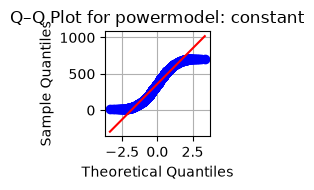

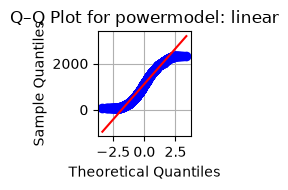

constant: p = 1.2651506724510152e-23 (not normal)
linear: p = 1.5102582064747324e-21 (not normal)
p-value Mann-Whitney U test: 4.94318155008367e-304
Significantly Different!
OPENDC
cubic: p = 3.695144361893302e-24 (not normal)
square: p = 3.69980688182608e-24 (not normal)
linear: p = 4.4791084947849346e-24 (not normal)
sqrt: p = 5.445303265629575e-23 (not normal)
constant: p = 3.695112487980541e-24 (not normal)
p-value Kruskal–Wallis test = 7.000091424635412e-219
Significantly Different!
SIMGRID


In [13]:
for simulator in simulators:
    print(simulator.upper())
    check_if_diff(super_df[super_df["simulator"] == simulator], "powermodel")

# Results

In [14]:
fs = 13

In [15]:
linestyles = {
    "constant": "solid",
    "ground truth": "solid",
    "linear": "dotted",
    "cubic": "dashed",
    "sqrt": "dashdot",
    "square": (3, 1, 1.5, 1, 1.5, 1)
}

In [16]:
colors = {
    "ground truth": "black",
    "opendc": "#377eb8",
    "dissectcf": "#984ea3",
    "cloudsim": "#4daf4a",
    "networkcloudsim": "#f781bf",
    "simgrid": "#ff7f00",
}

## Best selection

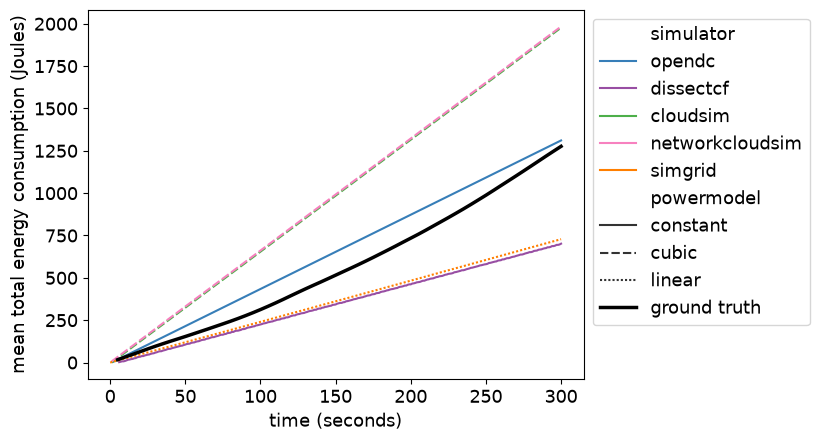

In [17]:
dfs = []
for simulator in simulators:
    sim_df = sim_dfs[simulator]
    df = sim_df[(sim_df["powermodel"] == best_combos[simulator])] 
    df = df.groupby(["powermodel", "time"])["joules_total"].mean().reset_index()
    df["simulator"] = simulator
    df["joules_total"] = pd.to_numeric(df["joules_total"], errors="coerce")
    df["time"] = pd.to_numeric(df["time"], errors="coerce")

    dfs.append(df)


merged_df = reduce(
    lambda left, right: pd.merge(left, right, on=["powermodel", "time", "simulator", "joules_total"], how="outer", suffixes=('', '_dup')),
    dfs
)


sns.lineplot(
    data=merged_df,
    x="time",
    y="joules_total",
    hue="simulator",
    style="powermodel",
    dashes=True,
    palette=colors
)

# Add ground truth
df = sim_dfs["cloudsim"][["time", "joules_total_correct"]].dropna(subset=["joules_total_correct"]).groupby(["time"]).mean().reset_index()

plt.plot(
    df["time"],
    df["joules_total_correct"],
    color="black",
    linewidth=2.5,
    label="ground truth"
)

plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
plt.xlabel("time (seconds)", fontsize=fs)
plt.ylabel("mean total energy consumption (Joules)", fontsize=fs)
plt.legend(bbox_to_anchor=(1, 1), loc='upper left', fontsize=fs)

plt.savefig("../mean_total_pwr.pdf", bbox_inches="tight")

## All over time

In [18]:
def graph_over_time(ax, system, scenario, users, idx):
    dfs = []
    for simulator in simulators:
        sim_df = sim_dfs[simulator]
        df = sim_df[(sim_df["test_system"] == system) &
                    (sim_df["scenario"] == scenario) &
                    (sim_df["users"] == users)] 
        df = df.groupby(["powermodel", "time"])["joules_total"].mean().reset_index()
        df["simulator"] = simulator
        df["joules_total"] = pd.to_numeric(df["joules_total"], errors="coerce")
        df["time"] = pd.to_numeric(df["time"], errors="coerce")
        
        dfs.append(df)

        
    merged_df = reduce(
        lambda left, right: pd.merge(left, right, on=["powermodel", "time", "simulator", "joules_total"], how="outer", suffixes=('', '_dup')),
        dfs
    )

    
    sns.lineplot(
        data=merged_df,
        x="time",
        y="joules_total",
        hue="simulator",
        style="powermodel",
        ax=ax,
        dashes=True,    
        palette=colors
    )

    #print(sim_dfs)
    df = sim_dfs["cloudsim"].query(f"scenario=='{scenario}' and users==@users and test_system=='{system}'")
    df = df[["time", "joules_total_correct"]].dropna(subset=["joules_total_correct"]).groupby(["time"]).mean().reset_index()
    ax.plot(
        df["time"],
        df["joules_total_correct"],
        color="black",
        linewidth=2.5,
        label="ground truth"
    )

    if i != 0:
        ax.get_legend().remove()
    
    ax.set_xlabel("time (seconds)", fontsize=12)
    ax.set_ylabel("mean total energy consumption (Joules)", fontsize=12)


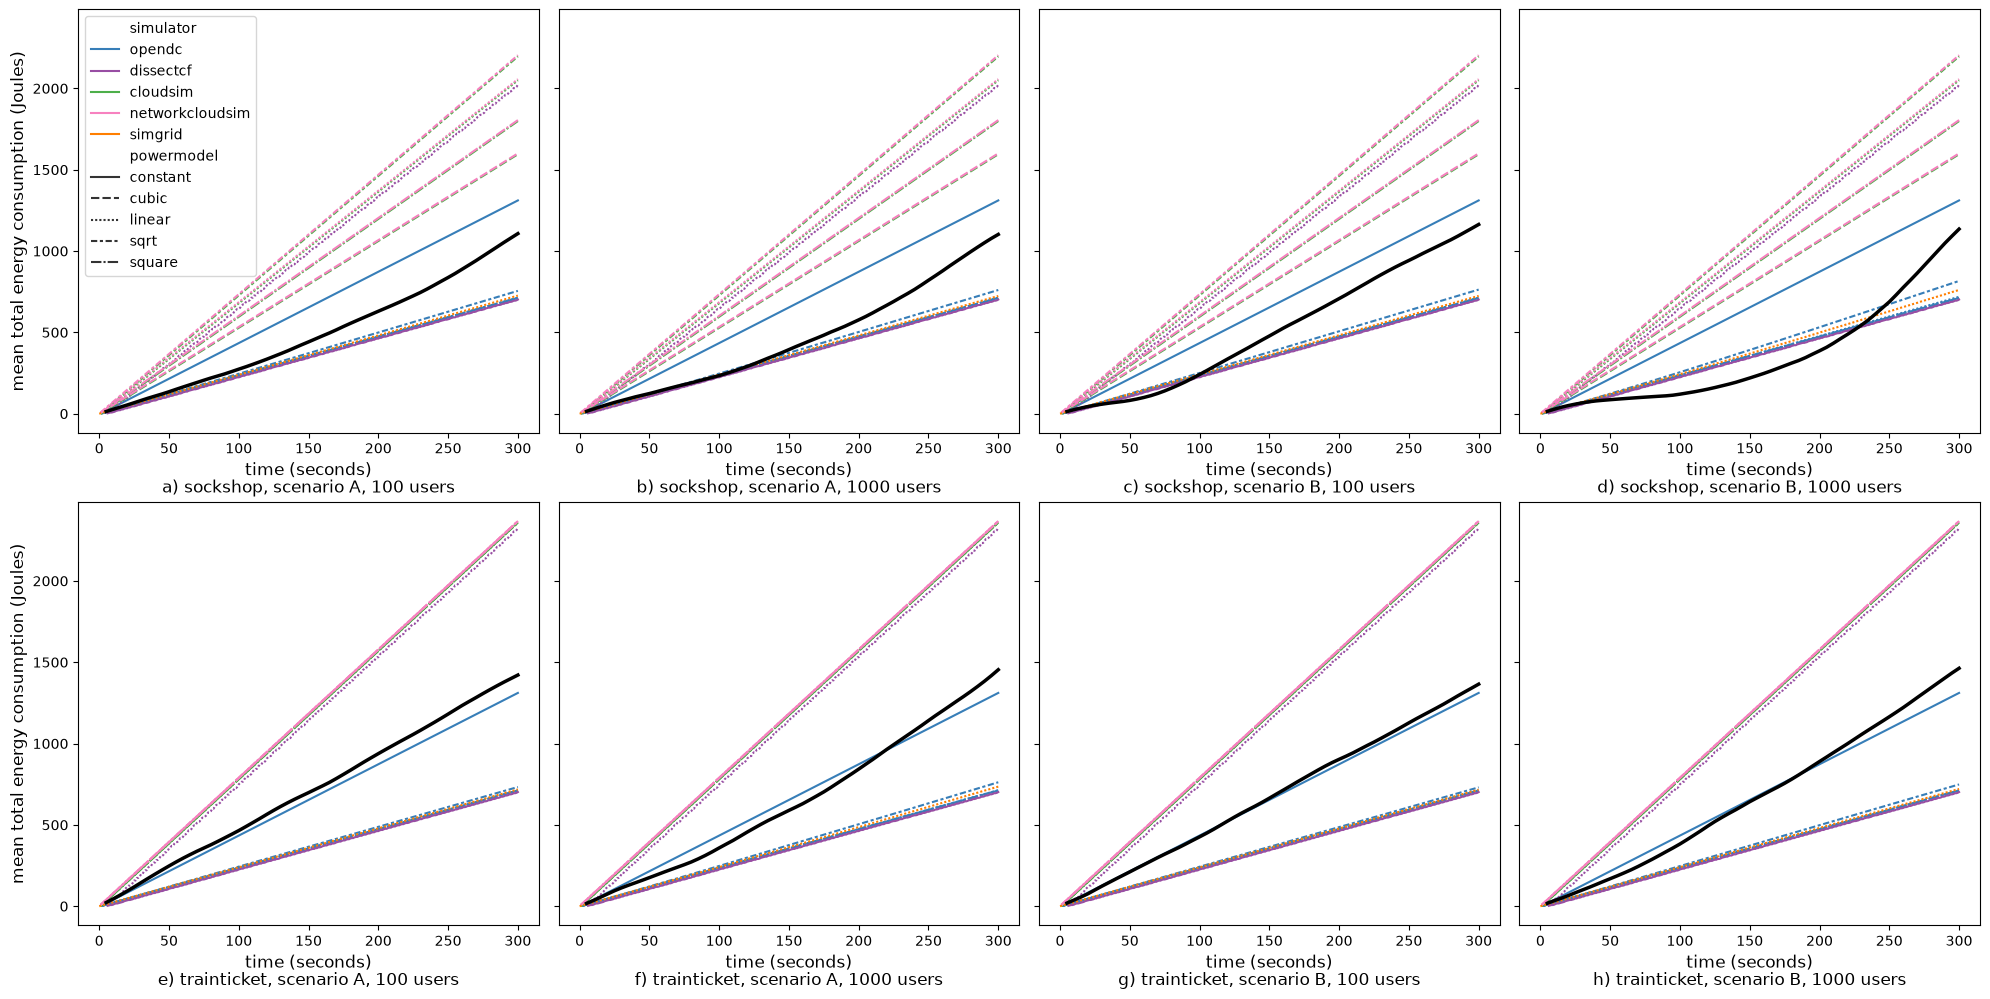

In [19]:
from itertools import product

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10), sharex=False, sharey=True)
axes = axes.flatten()

combinations = list(product(["sockshop", "trainticket"], ["A", "B"], [100, 1000]))
for i, (ax, (system, scenario, users)) in enumerate(zip(axes, combinations)):
    graph_over_time(ax, system, scenario, users, i)
    
    ax.text(
        0.5, -0.13, f"{'abcdefgh'[i]}) {system}, scenario {scenario}, {users} users",  # centered below
        transform=ax.transAxes,
        ha='center',
        va='center',
        fontsize='large'
    )

plt.tight_layout()
plt.savefig("../multi_image_fig.pdf", bbox_inches="tight")
            

## CDF totals

Text(0, 0.5, 'CDF')

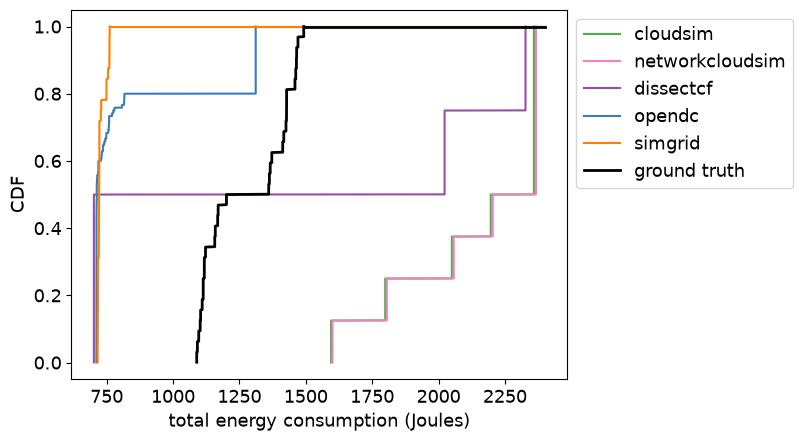

In [20]:
for simulator in simulators:
    sim_df = sim_dfs[simulator]
    totals = sim_df[sim_df["time"].round() == 300]["joules_total"].values
    sorted_totals = np.sort(totals)
    cdf = np.arange(1, len(sorted_totals) + 1) / len(sorted_totals)
    plt.plot(sorted_totals, cdf, label=simulator, color=colors[simulator])
    plt.plot(
        [sorted_totals[-1], 2400],
        [cdf[-1], cdf[-1]],
        color=colors[simulator]
    )

totals = sim_df[sim_df["time"].round() == 300]["joules_total_correct"].values
sorted_totals = np.sort(totals)
cdf = np.arange(1, len(sorted_totals) + 1) / len(sorted_totals)
plt.plot(sorted_totals, cdf, label="ground truth", color="black", linewidth=2)
plt.plot(
    [sorted_totals[-1], 2400],
    [cdf[-1], cdf[-1]],
    color="black",
    linewidth=2
)

plt.xticks(fontsize=fs)
plt.yticks(fontsize=fs)
plt.legend(bbox_to_anchor=(1, 1), loc='upper left', fontsize=fs)
plt.xlabel("total energy consumption (Joules)", fontsize=fs)
plt.ylabel("CDF", fontsize=fs)

In [21]:
def cdf_system(ax, system):
    cdf_data = []
    for simulator in simulators:
        powermodel = best_combos[simulator]
        sim_df = sim_dfs[simulator]
        totals = sim_df[(sim_df["time"].round() == 300) & (sim_df["powermodel"] == powermodel) & (sim_df["test_system"] == system)]["joules_total"].values # (sim_df["test_system"] == system)]

        sorted_totals = np.sort(totals)
        cdf = np.arange(1, len(sorted_totals) + 1) / len(sorted_totals)
        ax.plot(sorted_totals, cdf, label=f"{simulator} - {powermodel}", color=colors[simulator], linestyle=linestyles[powermodel])
        ax.plot(
            [sorted_totals[-1], 2400],
            [cdf[-1], cdf[-1]],
            color=colors[simulator]
        )
        
    
    totals = sim_df[(sim_df["time"].round() == 300) & (sim_df["test_system"] == system)]["joules_total_correct"].values
    sorted_totals = np.sort(totals)
    cdf = np.arange(1, len(sorted_totals) + 1) / len(sorted_totals)
    ax.plot(sorted_totals, cdf, label="ground truth", color="black", linewidth=2)
    ax.plot(
        [sorted_totals[-1], 2400],
        [cdf[-1], cdf[-1]],
        color="black",
        linewidth=2
    )



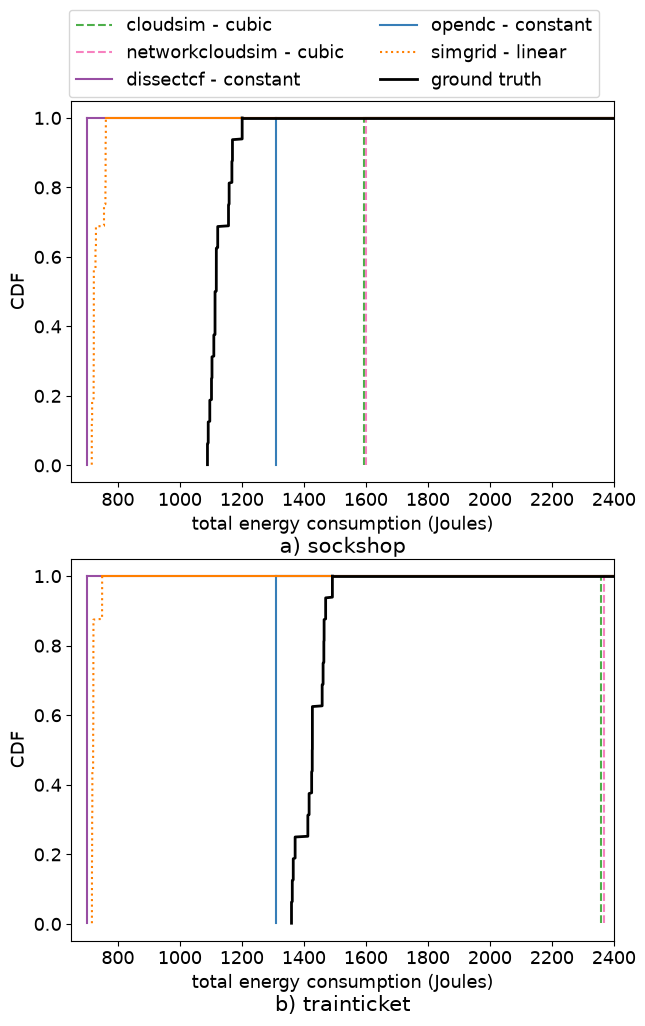

In [22]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(7, 10), sharex=False, sharey=False)
axes = axes.flatten()

combinations = ["sockshop", "trainticket"]
for i, (ax, system) in enumerate(zip(axes, combinations)):
    cdf_system(ax, system)
    
    ax.text(
        0.5, -0.17,f"{'abcdefgh'[i]}) {system}",
        transform=ax.transAxes,
        ha='center',
        va='center',
        fontsize=fs+2
    )

    ax.tick_params(labelsize=fs)
    ax.set_xlabel("total energy consumption (Joules)", fontsize=fs)
    ax.set_ylabel("CDF", fontsize=fs) 
    ax.set_xlim(650, 2400)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05),
    fontsize=fs,
    ncol=2
)
plt.subplots_adjust(top=0.95)
#plt.tight_layout()
plt.savefig("../double_cdf.pdf", bbox_inches="tight")
# fig.tight_layout()

## Difference between CloudSim and NetworkCloudSim

In [23]:
cloudsim = sim_dfs["cloudsim"][["joules_total", "time"]].groupby(["time"])["joules_total"].mean().reset_index().rename(columns={"joules_total": "joules_total_cloudsim"})
networkcloudsim = sim_dfs["networkcloudsim"][["joules_total", "time"]].groupby(["time"])["joules_total"].mean().reset_index().rename(columns={"joules_total": "joules_total_networkcloudsim"})
merged = pd.merge(cloudsim, networkcloudsim, on="time")
merged["joules_total_diff"] = merged["joules_total_networkcloudsim"] - merged["joules_total_cloudsim"]
merged["joules_total_diff"].describe()



count    3.000000e+02
mean     7.281771e+00
std      1.341917e-13
min      7.281771e+00
25%      7.281771e+00
50%      7.281771e+00
75%      7.281771e+00
max      7.281771e+00
Name: joules_total_diff, dtype: float64

In [24]:
list(sim_dfs.values())[0].columns

Index(['time', 'joules_total', 'joules', 'time_diff', 'host_power',
       'joules_correct', 'joules_total_correct', 'error_total', 'error',
       'rel_error_total', 'rel_error', 'policy', 'powermodel', 'run',
       'workload', 'test_system', 'scenario', 'users', 'repetition',
       'rel_error_total_abs', 'simulator'],
      dtype='str')

# Determinacy

In [25]:
for simulator in simulators:
    sim_df = sim_dfs[simulator]
    df = sim_df

    group_cols = ["time", "scenario", "repetition", "users"]

    df["watt"] = df["joules"]/df["time_diff"]

    std_df = df.groupby(group_cols)["watt"].std().reset_index(name="std")

    print(simulator + " stdev: mean=" + str(std_df["std"].mean()))



cloudsim stdev: mean=0.0887577384273578
networkcloudsim stdev: mean=0.08875773842735701
dissectcf stdev: mean=0.48362530219488303
opendc stdev: mean=0.15973152047968375
simgrid stdev: mean=3.4124647384170898e-06


# P-values correction

In [26]:
def benjamini_hochberg(p_values, alpha=0.05):
    """
    Apply the Benjamini-Hochberg (BH) procedure for controlling
    the False Discovery Rate (FDR).

    Parameters
    ----------
    p_values : array-like
        List or array of p-values.
    alpha : float, default=0.05
        Desired FDR level.

    Returns
    -------
    pandas.DataFrame
        DataFrame containing:
        - p_value: original p-value
        - p_adjusted: BH-adjusted p-value
        - rejected: whether H0 is rejected at the given alpha
    """
    
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)

    # Sort p-values
    order = np.argsort(p_values)
    ranked_pvals = p_values[order]

    # Compute adjusted p-values
    adjusted = ranked_pvals * m / np.arange(1, m + 1)

    # Enforce monotonicity
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    # Restore original order
    adjusted_original = np.empty(m)
    adjusted_original[order] = adjusted

    # Determine significance
    rejected = adjusted_original <= alpha

    return pd.DataFrame({
        "p_value": p_values,
        "p_adjusted": adjusted_original,
        "rejected": rejected
    })

# pvals = [0.001, 0.012, 0.018, 0.041, 0.08, 0.15]

results = benjamini_hochberg(p_values, alpha=0.05)
print(results)

          p_value     p_adjusted  rejected
0    1.000000e+00   1.000000e+00     False
1    0.000000e+00   0.000000e+00      True
2    3.111650e-01   3.394527e-01     False
3    0.000000e+00   0.000000e+00      True
4    0.000000e+00   0.000000e+00      True
5    0.000000e+00   0.000000e+00      True
6    0.000000e+00   0.000000e+00      True
7   1.081803e-148  1.622704e-148      True
8    3.143884e-14   3.772660e-14      True
9    2.311094e-14   3.081459e-14      True
10  4.943182e-304  9.886363e-304      True
11  7.000091e-219  1.200016e-218      True


In [33]:
print(p_values)
sorted_pvals = sorted(p_values)
print(sorted_pvals[8])


[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(4.94318155008367e-304), np.float64(7.000091424635412e-219), np.float64(1.0818026028010726e-148), np.float64(2.311094190823102e-14), np.float64(3.1438837427566445e-14), np.float64(0.31116496485516876), np.float64(1.0)]
2.311094190823102e-14
